# Ratio AUC vs. synapse fractions
Correlates the mean HyLight/Ca ratio AUC of each neuron-type × compartment with the fraction of each neuron's synapses that sits in that compartment (connectome).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

# ---------------------------------------------------------------
# Inputs
# ---------------------------------------------------------------
AUC_CSV = (
    "your/path/here/compartments_lowpass-4hz_AUC_zerocross_final.csv"
)
COUNTS_DIR = "your/path/here"   # holds somaanchored_100_<type>_df_counts.csv

# Cluster number -> compartment name, separately for each neuron type
CLUSTER_MAPS = {
    "Tm1": {0: "M2", 1: "M3", 2: "M9", 3: "Lo1"},
    "Mi1": {0: "M1", 1: "M5", 2: "M9", 3: "M10"},
    "Tm3": {0: "M1", 1: "M5", 2: "M8", 3: "M10", 4: "Lo1", 5: "Lo4"},
    "Mi9": {0: "M2", 1: "M3", 2: "M9", 3: "M10"},
    "L1":  {0: "La", 1: "M1", 2: "M5"},
    "Tm9": {0: "M3", 1: "Lo1"},
    "L2":  {0: "La", 1: "M2"},
    "Tm2": {0: "M2", 1: "M3", 2: "M9", 3: "Lo1"},
}

# Point colors; this order is also the legend order
NEURON_TYPE_COLORS = {
    "Tm1": "#9ecae1",
    "Mi1": "#6baed6",
    "Tm3": "#4292c6",
    "Mi9": "#F43333",
    "Tm9": "#2171b5",
    "Tm2": "#c6dbef",
    "L1":  "#C3263B",
    "L2":  "#1B49AC",
}

In [2]:
def load_synapse_counts(neuron_type, cluster_map):
    """Synapse counts per neuron and cluster for one neuron type, with compartment names added."""
    path = f"{COUNTS_DIR}/somaanchored_100_{neuron_type}_df_counts.csv"
    df = pd.read_csv(path)

    df["Compartment"] = df["cluster"].map(cluster_map)
    unmapped = sorted(df.loc[df["Compartment"].isna(), "cluster"].unique())
    if unmapped:
        raise ValueError(f"{path}: cluster IDs {unmapped} are not in the cluster map for {neuron_type}")

    df["neuron_type"] = neuron_type
    df["total"] = df["pre"] + df["post"]
    df["neuron_compartment_id"] = neuron_type + "_" + df["Compartment"].str.lower()
    return df


def summarize_synapses(counts):
    """
    For each neuron type × compartment, means over neurons of:
      - pre_mean, post_mean, total_mean: synapse numbers in the compartment
      - *_frac_of_neuron: fraction of the neuron's pre, post and total synapses in the compartment
    """
    counts = counts.copy()
    neuron_totals = counts.groupby(["neuron_type", "bodyId"])[["pre", "post", "total"]].transform("sum")
    for col in ["pre", "post", "total"]:
        counts[f"{col}_frac_of_neuron"] = counts[col] / neuron_totals[col]

    return counts.groupby(["neuron_compartment_id", "neuron_type", "Compartment"], as_index=False).agg(
        n_neurons=("bodyId", "nunique"),
        pre_mean=("pre", "mean"),
        post_mean=("post", "mean"),
        total_mean=("total", "mean"),
        pre_frac_of_neuron=("pre_frac_of_neuron", "mean"),
        post_frac_of_neuron=("post_frac_of_neuron", "mean"),
        total_frac_of_neuron=("total_frac_of_neuron", "mean"),
    )


def summarize_auc(auc_df, neuron_types):
    """Mean ratio AUC for each neuron type × compartment (neuron types matched case-insensitively)."""
    auc = auc_df.copy()
    name_by_lower = {nt.lower(): nt for nt in neuron_types}
    auc["neuron_type"] = auc["Genotype"].astype(str).str.lower().map(name_by_lower)
    auc = auc.dropna(subset=["neuron_type"])
    auc["neuron_compartment_id"] = auc["neuron_type"] + "_" + auc["Compartment"].astype(str).str.lower()

    return auc.groupby("neuron_compartment_id", as_index=False).agg(
        n_traces=("Trace", "count"),
        AUC_ratio_mean=("AUC_ratio", "mean"),
    )

In [3]:
counts = pd.concat(
    [load_synapse_counts(nt, cmap) for nt, cmap in CLUSTER_MAPS.items()],
    ignore_index=True,
)
auc_df = pd.read_csv(AUC_CSV)

merged = summarize_synapses(counts).merge(
    summarize_auc(auc_df, CLUSTER_MAPS), on="neuron_compartment_id", how="inner"
)
merged

,neuron_compartment_id,neuron_type,Compartment,n_neurons,pre_mean,post_mean,total_mean,pre_frac_of_neuron,post_frac_of_neuron,total_frac_of_neuron,n_traces,AUC_ratio_mean
0,L1_m1,L1,M1,90,51.188889,78.077778,129.266667,0.508707,0.263096,0.326116,54,1.229663
1,L1_m5,L1,M5,90,44.722222,23.877778,68.600000,0.446886,0.086987,0.179804,23,2.490618
2,L2_m2,L2,M2,78,132.153846,160.128205,292.282051,0.911110,0.418878,0.551891,49,1.979553
3,Mi1_m1,Mi1,M1,100,75.360000,205.600000,280.960000,0.202745,0.441432,0.335478,9,0.441928
4,Mi1_m10,Mi1,M10,100,90.360000,28.630000,118.990000,0.243353,0.061558,0.142272,53,0.603186
5,Mi1_m5,Mi1,M5,100,37.210000,115.620000,152.830000,0.100051,0.248298,0.182469,22,0.384684
6,Mi1_m9,Mi1,M9,100,168.770000,115.790000,284.560000,0.453851,0.248712,0.339780,48,0.648547
7,Mi9_m10,Mi9,M10,100,44.960000,39.680000,84.640000,0.285359,0.118029,0.171411,14,1.615272
8,Mi9_m3,Mi9,M3,100,64.940000,175.320000,240.260000,0.404936,0.519179,0.482679,19,0.701678
9,Mi9_m9,Mi9,M9,100,39.930000,26.640000,66.570000,0.246286,0.079227,0.132940,12,1.365179


In [4]:
# x-axis columns and labels for each synapse measure
X_VARS = {
    "fraction": {
        "pre_frac_of_neuron": "Presynaptic fraction",
        "post_frac_of_neuron": "Postsynaptic fraction",
        "total_frac_of_neuron": "Total synaptic fraction",
    },
    "count": {
        "pre_mean": "Presynapses per neuron",
        "post_mean": "Postsynapses per neuron",
        "total_mean": "Total synapses per neuron",
    },
}
Y_VAR = "AUC_ratio_mean"

ALL_FIT_STYLE = dict(color="0.50", linewidth=1.25, linestyle="--")   # fit through all neuron types
EXCL_FIT_STYLE = dict(color="black", linewidth=1.55, linestyle="-")  # fit without exclude_from_fit


def _pearson(x, y):
    if len(x) >= 3 and np.std(x) > 0 and np.std(y) > 0:
        r, p = pearsonr(x, y)
        return float(r), float(p)
    return np.nan, np.nan


def _format_r(r):
    return "n/a" if np.isnan(r) else f"{r:.2f}"


def _format_p(p):
    if np.isnan(p):
        return "n/a"
    if p < 1e-4:
        return f"{p:.1e}"
    if p < 1e-3:
        return f"{p:.4f}"
    return f"{p:.3f}"


def _plot_fit(ax, x, y, **line_kwargs):
    """Draw a least-squares line across the range of x."""
    if len(x) >= 2 and np.std(x) > 0:
        slope, intercept = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 250)
        ax.plot(xs, slope * xs + intercept, **line_kwargs)


def plot_auc_vs_synapses(
    merged,
    neuron_type_colors,
    synapse_measure="fraction",
    exclude_from_fit=("Mi9", "L1"),
    y_label="Mean AUC Ratio",
    x_limits=None,
    y_limits=None,
    figsize_per_panel=(3.0, 3.0),
    legend_width=1.45,
    point_size=48,
    point_alpha=0.85,
    show_line_stats=True,
    show_fit_legend=True,
    axis_label_fontsize=14,
    tick_labelsize=12,
    axis_labelpad=7,
    save_prefix=None,
    dpi=300,
):
    """
    One scatter panel per synapse measure (pre, post, total) against mean ratio AUC.
    Each panel has a dashed fit through all neuron types and a solid fit without the
    types in `exclude_from_fit`, with Pearson r and p for both.

    synapse_measure:
        "fraction": fraction of each neuron's synapses that lies in the compartment
        "count":    number of synapses per neuron in the compartment

    Returns (corr_table, fig, axes).
    """
    if synapse_measure not in X_VARS:
        raise ValueError(f"synapse_measure must be one of {list(X_VARS)}, not {synapse_measure!r}")
    x_vars = X_VARS[synapse_measure]

    excluded = {nt.lower() for nt in exclude_from_fit}

    # Draw and legend order follow the color dictionary; types without a color get tab10 colors.
    present = set(merged["neuron_type"].dropna())
    order = [nt for nt in neuron_type_colors if nt in present]
    missing = sorted(present - set(neuron_type_colors), key=str.lower)
    colors = dict(neuron_type_colors)
    colors.update({nt: plt.get_cmap("tab10")(i % 10) for i, nt in enumerate(missing)})
    order += missing

    n_panels = len(x_vars)
    panel_w, panel_h = figsize_per_panel
    fig_w = panel_w * n_panels + legend_width
    fig, axes = plt.subplots(
        1, n_panels, figsize=(fig_w, panel_h + 0.45), dpi=dpi,
        sharey=True, squeeze=False, facecolor="white",
    )
    axes = axes[0]

    stats_box = dict(boxstyle="round,pad=0.24", facecolor="white", edgecolor="none", alpha=0.82)
    corr_rows = []

    for ax, (x, x_label) in zip(axes, x_vars.items()):
        d = merged[["neuron_type", x, Y_VAR]].dropna()
        d_incl = d[~d["neuron_type"].str.lower().isin(excluded)]

        for nt in order:
            g = d[d["neuron_type"] == nt]
            if len(g):
                ax.scatter(
                    g[x], g[Y_VAR], s=point_size, facecolor=colors[nt], alpha=point_alpha,
                    edgecolor="black", linewidth=0.55, zorder=3,
                )

        x_all, y_all = d[x].to_numpy(float), d[Y_VAR].to_numpy(float)
        x_incl, y_incl = d_incl[x].to_numpy(float), d_incl[Y_VAR].to_numpy(float)

        _plot_fit(ax, x_all, y_all, **ALL_FIT_STYLE, alpha=0.98, zorder=1)
        _plot_fit(ax, x_incl, y_incl, **EXCL_FIT_STYLE, zorder=2)

        r_all, p_all = _pearson(x_all, y_all)
        r_incl, p_incl = _pearson(x_incl, y_incl)
        corr_rows.append({
            "x": x,
            "y": Y_VAR,
            "pearson_r_all": r_all,
            "pearson_p_all": p_all,
            "n_all": len(d),
            "pearson_r_excluding": r_incl,
            "pearson_p_excluding": p_incl,
            "n_excluding": len(d_incl),
            "excluded_neuron_types": ", ".join(exclude_from_fit),
        })

        if show_line_stats:
            stats_lines = [("All", r_all, p_all, ALL_FIT_STYLE), ("Excl.", r_incl, p_incl, EXCL_FIT_STYLE)]
            for i, (name, r, p, style) in enumerate(stats_lines):
                ax.text(
                    0.04, 0.96 - 0.17 * i,
                    f"{name}: $r$ = {_format_r(r)}, $p$ = {_format_p(p)}",
                    transform=ax.transAxes, fontsize=8, color=style["color"],
                    ha="left", va="top", bbox=stats_box, zorder=8,
                )

        ax.set_xlabel(x_label, fontsize=axis_label_fontsize, labelpad=axis_labelpad)
        ax.set_ylabel(y_label, fontsize=axis_label_fontsize, labelpad=axis_labelpad)
        if x_limits is not None:
            ax.set_xlim(x_limits)
        if y_limits is not None:
            ax.set_ylim(y_limits)

        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_linewidth(0.9)
        # labelleft=True keeps y tick labels on every panel despite sharey
        ax.tick_params(labelsize=tick_labelsize, width=0.9, length=3.5, direction="out", pad=3, labelleft=True)
        ax.margins(x=0.07, y=0.10)
        ax.set_box_aspect(1.0)

    # Legends in the extra space to the right of the panels
    right_edge = panel_w * n_panels / fig_w
    legend_x = min(right_edge + 0.035, 0.98)
    legend_kwargs = dict(loc="center left", frameon=False, fontsize=8.5, title_fontsize=9.5, borderaxespad=0.0)

    type_handles = [
        Line2D([0], [0], marker="o", linestyle="None", markersize=np.sqrt(point_size) * 0.85,
               markerfacecolor=colors[nt], markeredgecolor="black", markeredgewidth=0.55, label=str(nt))
        for nt in order
    ]
    fig.legend(handles=type_handles, bbox_to_anchor=(legend_x, 0.57), title="Neuron type",
               handletextpad=0.55, labelspacing=0.55, **legend_kwargs)

    if show_fit_legend:
        excl_label = f"Excluding {', '.join(exclude_from_fit)}" if exclude_from_fit else "Restricted fit"
        fit_handles = [
            Line2D([0], [0], label="All neuron types", **ALL_FIT_STYLE),
            Line2D([0], [0], label=excl_label, **EXCL_FIT_STYLE),
        ]
        fig.legend(handles=fit_handles, bbox_to_anchor=(legend_x, 0.22), title="Linear fit",
                   handlelength=2.7, handletextpad=0.65, labelspacing=0.65, **legend_kwargs)

    fig.subplots_adjust(top=0.92, bottom=0.18, left=0.075, right=max(right_edge - 0.02, 0.70), wspace=0.38)

    if save_prefix is not None:
        file_word = "fractions" if synapse_measure == "fraction" else "counts"
        for ext in ("pdf", "png"):
            fig.savefig(f"{save_prefix}_mean_ratio_auc_vs_synapse_{file_word}_dual_fit.{ext}",
                        bbox_inches="tight", dpi=dpi, facecolor="white")

    plt.show()
    return pd.DataFrame(corr_rows), fig, axes

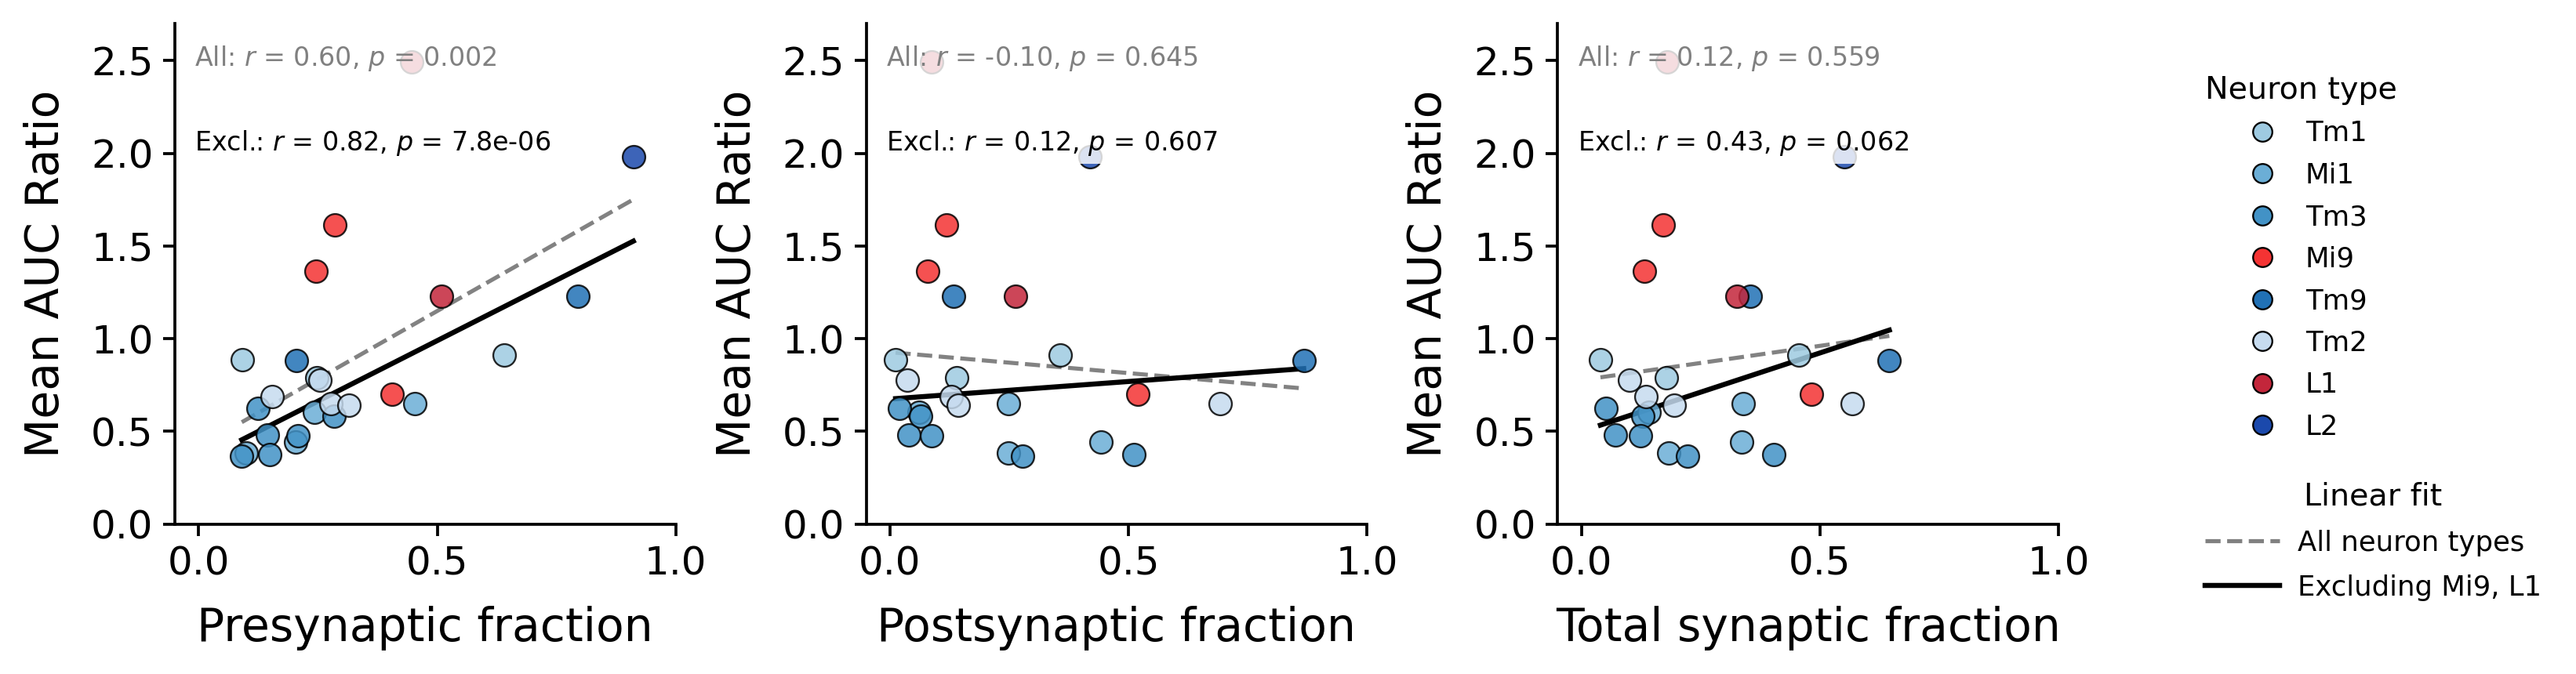

,x,y,pearson_r_all,pearson_p_all,n_all,pearson_r_excluding,pearson_p_excluding,n_excluding,excluded_neuron_types
0,pre_frac_of_neuron,AUC_ratio_mean,0.597221,0.001621,25,0.824523,0.000008,20,"Mi9, L1"
1,post_frac_of_neuron,AUC_ratio_mean,-0.096855,0.645107,25,0.122415,0.607149,20,"Mi9, L1"
2,total_frac_of_neuron,AUC_ratio_mean,0.122838,0.558569,25,0.425060,0.061726,20,"Mi9, L1"


In [5]:
# Synapse fractions
corr_table, fig, axes = plot_auc_vs_synapses(
    merged,
    neuron_type_colors=NEURON_TYPE_COLORS,
    synapse_measure="fraction",
    exclude_from_fit=("Mi9", "L1"),
    y_label="Mean AUC Ratio",
    x_limits=(-0.05, 1),
    y_limits=(0, 2.7),
    point_size=48,
    point_alpha=0.85,
    show_line_stats=True,
    show_fit_legend=True,
    save_prefix=None,
)
corr_table